In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

df = pd.read_csv('M25_DA_A1_Dataset1.csv')

# Education Distribution & Grouping


In [2]:
df.columns
df['Education'] = df['Education'].str.strip()

In [3]:
df['Education'].isna().sum()
df = df[df['Education'].notna()]

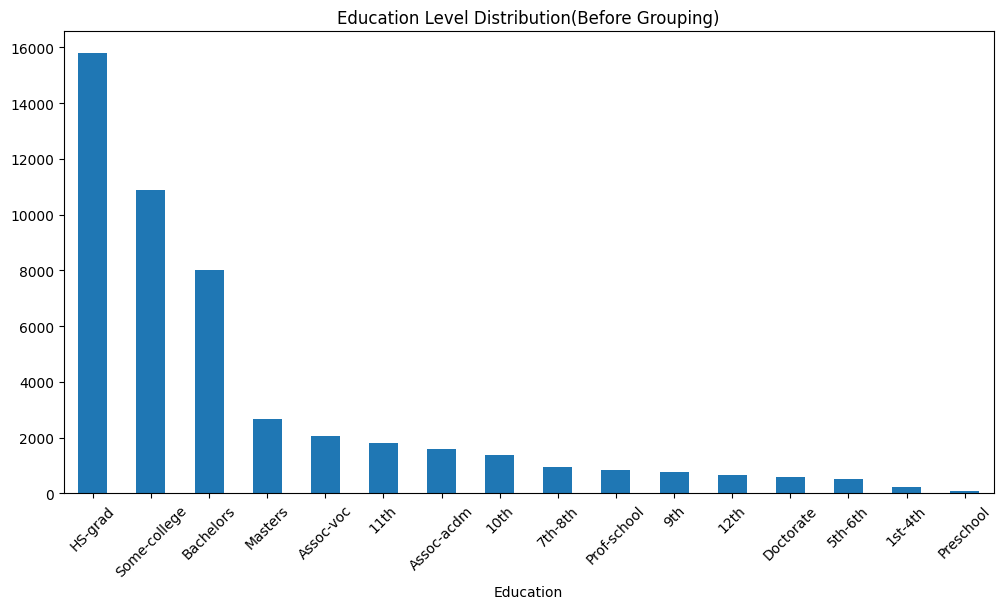

In [4]:
Education_counts = df['Education'].value_counts()
Education_counts.plot(kind='bar', figsize=(12, 6))
plt.title('Education Level Distribution(Before Grouping)')
plt.xticks(rotation=45)
plt.show()

In [5]:
Kinder_garden = ["Preschool"]
School= ["1st-4th", "5th-6th", "7th-8th"]
High_School = ["9th", "10th", "11th", "12th", "HS-grad", "Assoc-voc", "Assoc-acdm"]
Undergrad = ["Bachelors", "Some-college"]
Postgrad = ["Masters", "Prof-school", "Doctorate"]
df['Education_Level'] = 'Unknown'
df.loc[df['Education'].isin(Kinder_garden), 'Education_Level'] = 'Kindergarten'
df.loc[df['Education'].isin(School), 'Education_Level'] = 'School'
df.loc[df['Education'].isin(High_School), 'Education_Level'] = 'High School'
df.loc[df['Education'].isin(Undergrad), 'Education_Level'] = 'Undergraduate'
df.loc[df['Education'].isin(Postgrad), 'Education_Level'] = 'Postgraduate'

Education_Level
High School      24060
Undergraduate    18903
Postgraduate      4085
School            1711
Kindergarten        83
Name: count, dtype: int64


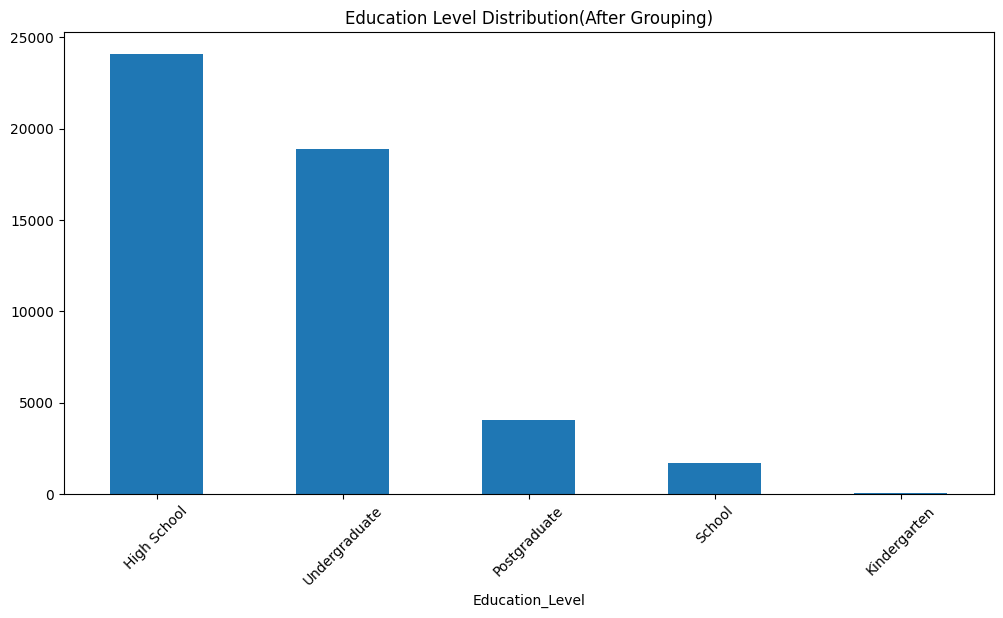

In [6]:
Education_Grouped_counts=df['Education_Level'].value_counts()
print(Education_Grouped_counts)
Education_Grouped_counts.plot(kind='bar', figsize=(12, 6))
plt.title('Education Level Distribution(After Grouping)')
plt.xticks(rotation=45)
plt.show()

# Age–Work Intensity Relationship and Grouping


In [7]:
df['Age'] = pd.to_numeric(df['Age'], errors='coerce')
df['Hours_per_week'] = pd.to_numeric(df['Hours_per_week'], errors='coerce')
df['Age'] = df['Age'].fillna(df[df['Age'] > 14]['Age'].mode()[0])
df['Hours_per_week'] = df['Hours_per_week'].fillna(df['Hours_per_week'].mode()[0])
age_mode = df['Age'].mode()[0]
hours_mode = df['Hours_per_week'].mode()[0]
df['Age'] = np.where(df['Age'] < 0, age_mode, df['Age'])
df['Hours_per_week'] = np.where(df['Hours_per_week'] < 0, hours_mode, df['Hours_per_week'])
df = df[(df['Age'] >= 14) & (df['Age'] > 0)]

In [8]:
df['Age_Group'] = pd.cut(df['Age'], 
                        bins=[0, 25, 35, 55, 65, float('inf')], 
                        labels=['Freshers', 'Early_Career', 'Mid_Career', 'Late_Career', 'Senior'],
                        right=False)
 
df['Work_Intensity'] = pd.cut(df['Hours_per_week'],
                             bins=[0, 1, 25, 41, 61, float('inf')],
                             labels=['Unemployed', 'Part_Time', 'Full_Time', 'Overtime', 'Excessive'],
                             right=False, include_lowest=True)

In [9]:
print("DISTRIBUTION COMPARISON")
print(f"Original Age: Mean={df['Age'].mean():.1f}, Std={df['Age'].std():.1f}, Unique={df['Age'].nunique()}")
print(f"Original Hours: Mean={df['Hours_per_week'].mean():.1f}, Std={df['Hours_per_week'].std():.1f}, Unique={df['Hours_per_week'].nunique()}")
print(f"Age Groups: {df['Age_Group'].nunique()} categories")
print(f"Work Intensity: {df['Work_Intensity'].nunique()} categories")

print("\nGROUPED DISTRIBUTIONS")
print(df['Age_Group'].value_counts().sort_index())
print("\n")
print(df['Work_Intensity'].value_counts())

DISTRIBUTION COMPARISON
Original Age: Mean=38.6, Std=13.7, Unique=74
Original Hours: Mean=40.4, Std=12.4, Unique=96
Age Groups: 5 categories
Work Intensity: 4 categories

GROUPED DISTRIBUTIONS
Age_Group
Freshers         8432
Early_Career    12577
Mid_Career      20964
Late_Career      4782
Senior           2087
Name: count, dtype: int64


Work_Intensity
Full_Time     29535
Overtime      12676
Part_Time      4955
Excessive      1676
Unemployed        0
Name: count, dtype: int64


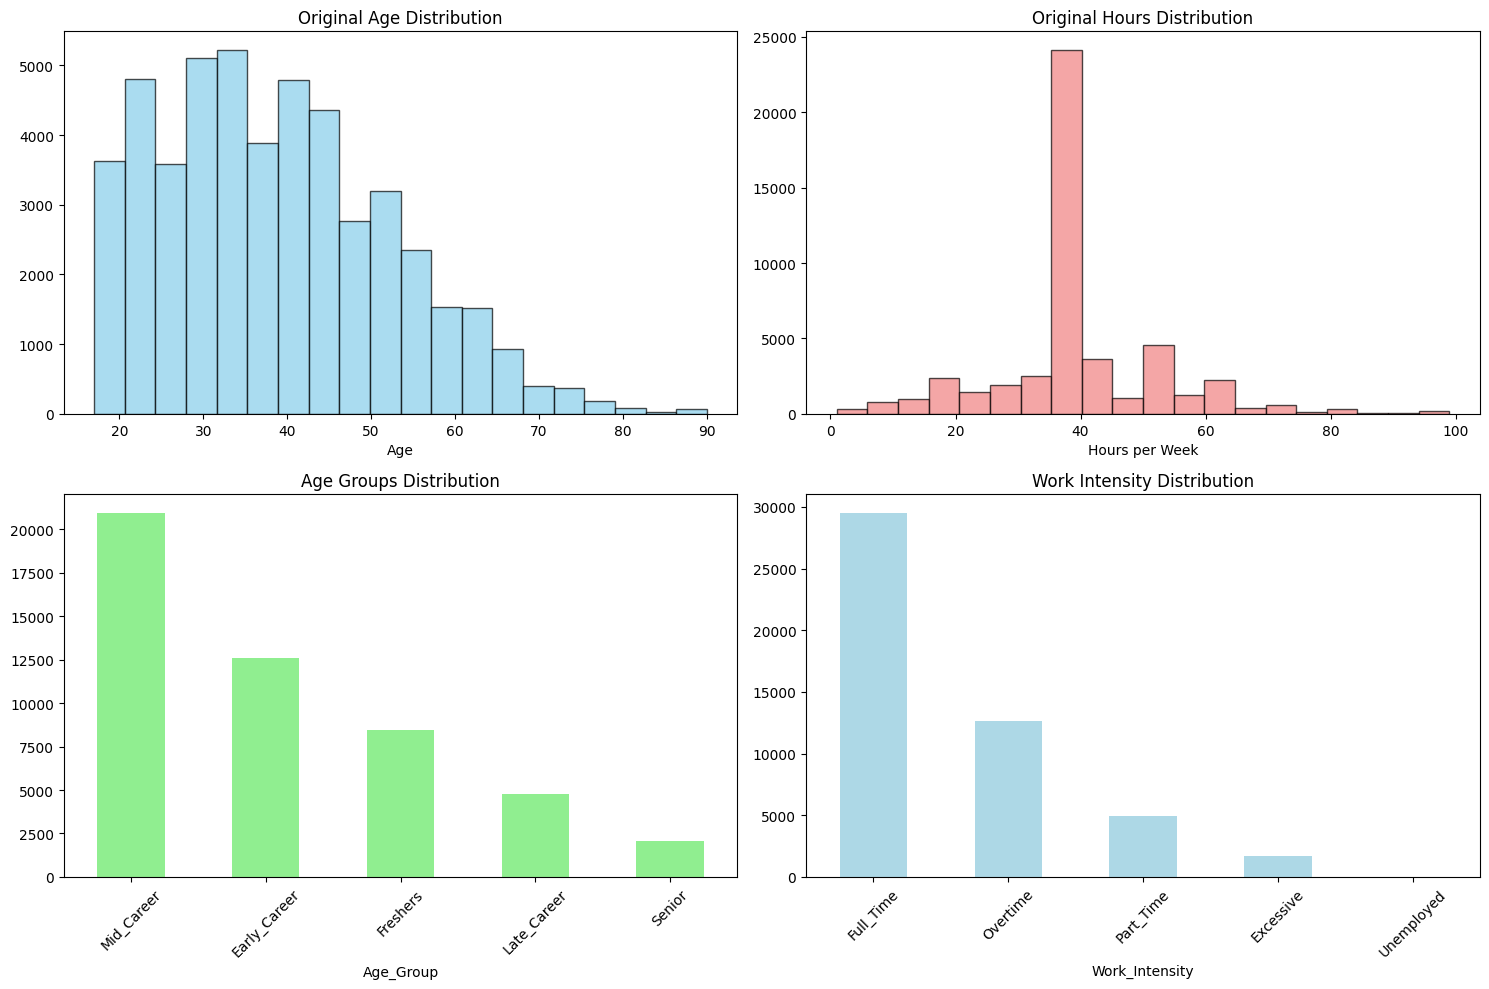

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Original distributions
axes[0,0].hist(df['Age'], bins=20, alpha=0.7, color='skyblue', edgecolor='black')
axes[0,0].set_title('Original Age Distribution')
axes[0,0].set_xlabel('Age')

axes[0,1].hist(df['Hours_per_week'], bins=20, alpha=0.7, color='lightcoral', edgecolor='black')
axes[0,1].set_title('Original Hours Distribution')
axes[0,1].set_xlabel('Hours per Week')

# Grouped distributions
df['Age_Group'].value_counts().plot(kind='bar', ax=axes[1,0], color='lightgreen')
axes[1,0].set_title('Age Groups Distribution')
axes[1,0].tick_params(axis='x', rotation=45)

df['Work_Intensity'].value_counts().plot(kind='bar', ax=axes[1,1], color='lightblue')
axes[1,1].set_title('Work Intensity Distribution')
axes[1,1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

Work_Intensity  Part_Time  Full_Time  Overtime  Excessive
Age_Group                                                
Freshers             2243       5207       897         85
Early_Career          609       8034      3469        465
Mid_Career            780      12387      6894        903
Late_Career           461       2968      1181        172
Senior                862        939       235         51

STATISTICAL TESTS
Chi-square statistic: 7108.0502
P-value: 0.0000
Significant relationship: Yes

CORRELATION ANALYSIS
Age-Hours correlation (original): 0.0716


<Figure size 1400x800 with 0 Axes>

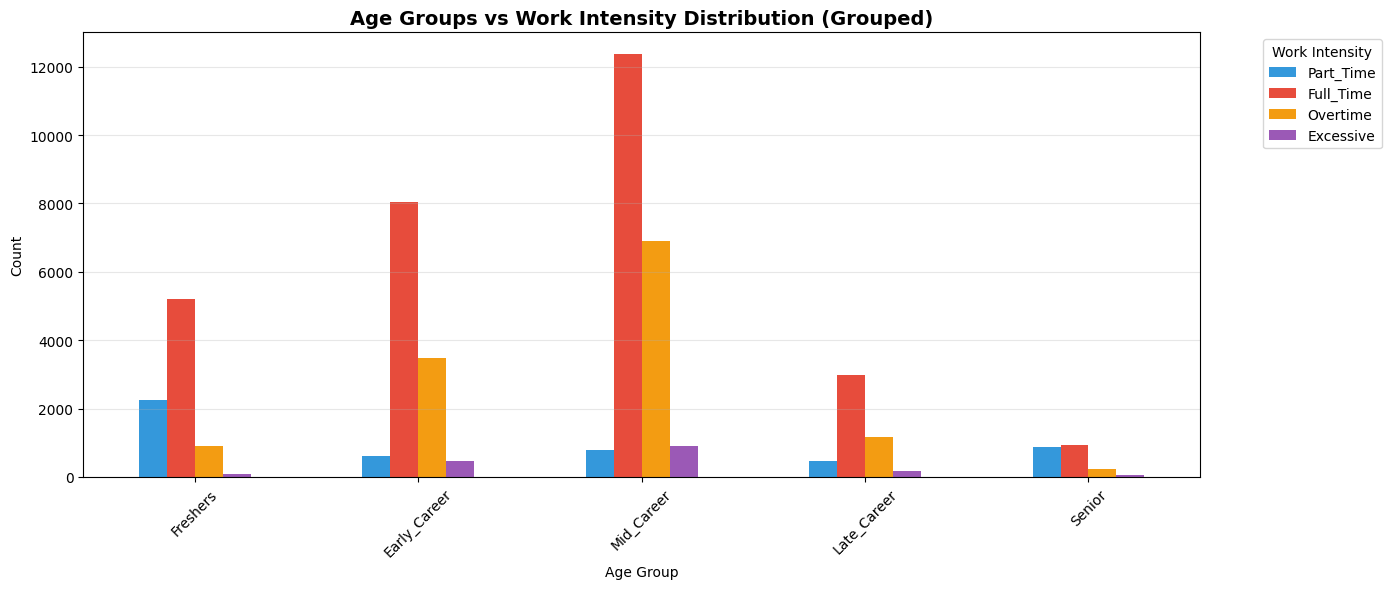

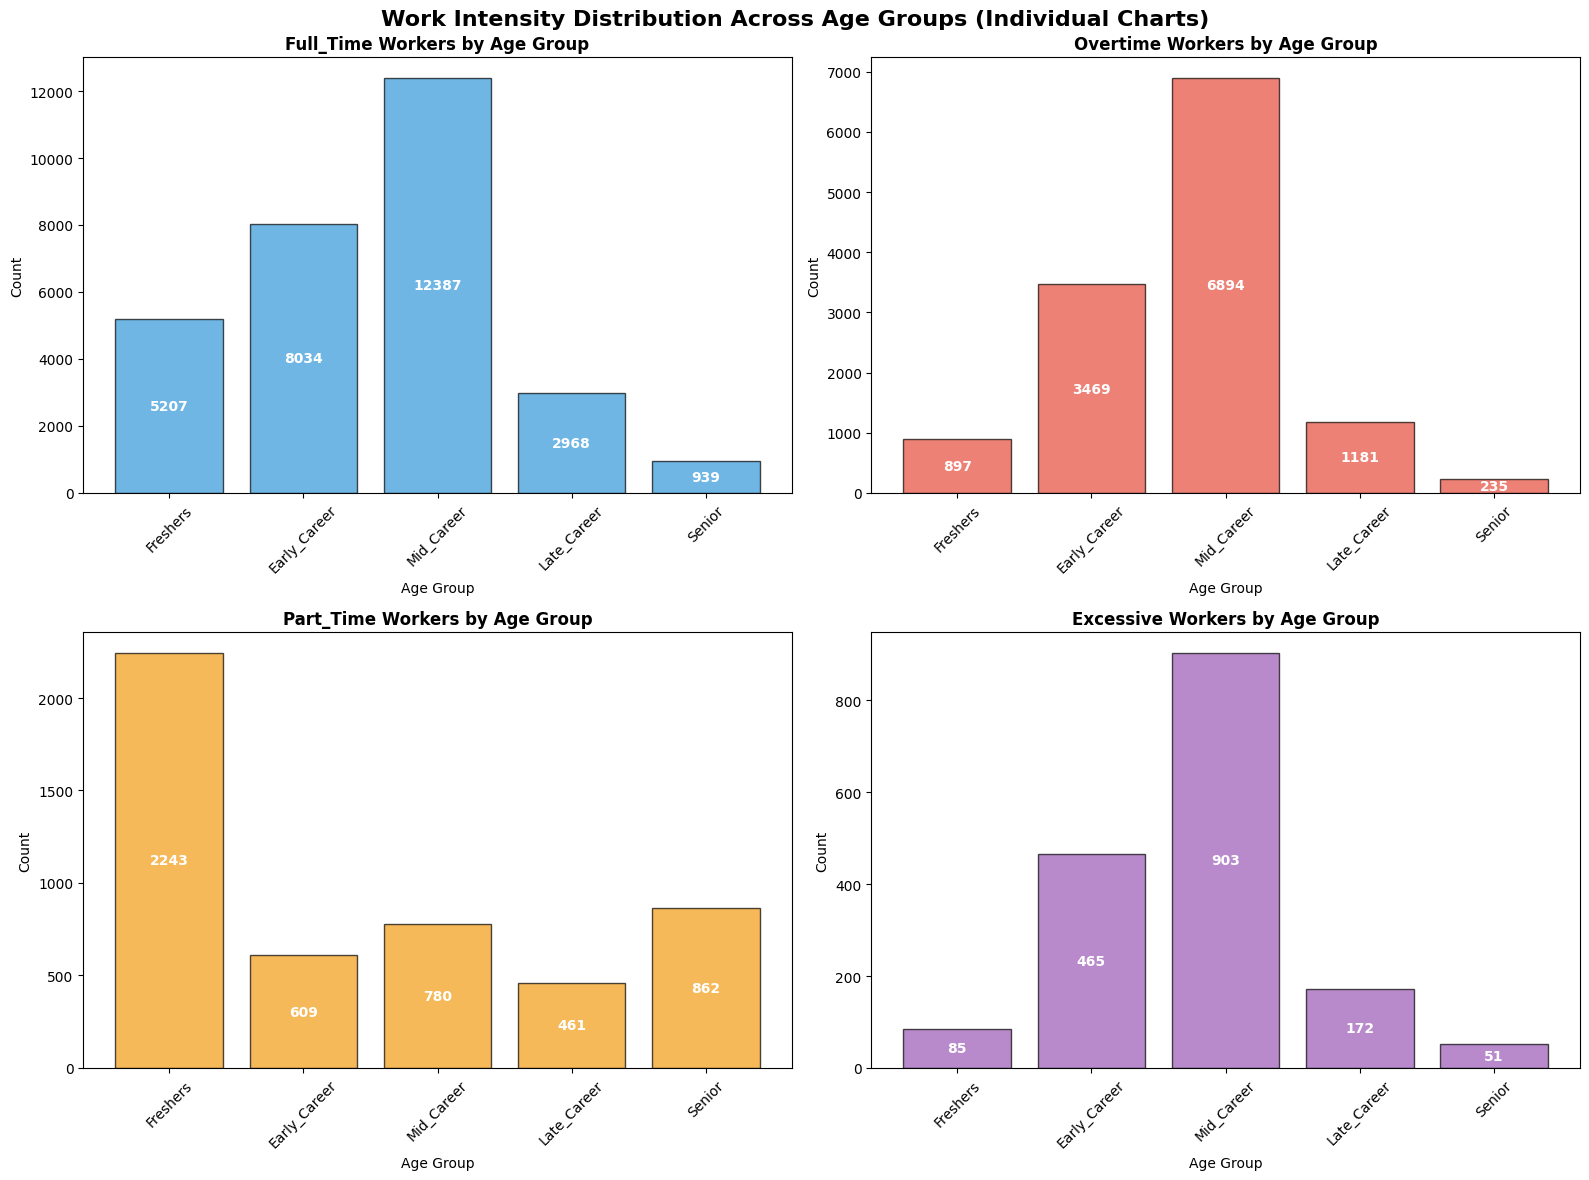

In [11]:
import numpy as np
from scipy.stats import chi2_contingency

crosstab = pd.crosstab(df['Age_Group'], df['Work_Intensity'])
print(crosstab)

conditions = [
    (df['Age'] < 35) & (df['Hours_per_week'] > 50),
    (df['Age'] >= 55) & (df['Hours_per_week'] > 45),
    df['Hours_per_week'] <= 35
]
choices = ['Young_Overworked', 'Senior_Overworked', 'Balanced']
df['Work_Life_Balance'] = np.select(conditions, choices, default='Standard')

chi2, p_value, dof, expected = chi2_contingency(crosstab)
print(f"\nSTATISTICAL TESTS")
print(f"Chi-square statistic: {chi2:.4f}")
print(f"P-value: {p_value:.4f}")
print(f"Significant relationship: {'Yes' if p_value < 0.05 else 'No'}")

print(f"\nCORRELATION ANALYSIS")
print(f"Age-Hours correlation (original): {df['Age'].corr(df['Hours_per_week']):.4f}")

plt.figure(figsize=(14, 8))
crosstab.plot(kind='bar', figsize=(14, 6), 
              color=['#3498db', '#e74c3c', '#f39c12', '#9b59b6'])
plt.title('Age Groups vs Work Intensity Distribution (Grouped)', fontsize=14, fontweight='bold')
plt.xlabel('Age Group')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.legend(title='Work Intensity', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

work_intensities = ['Full_Time', 'Overtime', 'Part_Time', 'Excessive']
colors = ['#3498db', '#e74c3c', '#f39c12', '#9b59b6']

for i, intensity in enumerate(work_intensities):
    intensity_data = crosstab[intensity]
    bars = axes[i].bar(intensity_data.index, intensity_data.values, color=colors[i], alpha=0.7, edgecolor='black')
    axes[i].set_title(f'{intensity} Workers by Age Group', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Age Group')
    axes[i].set_ylabel('Count')
    axes[i].tick_params(axis='x', rotation=45)
    
    for bar in bars:
        height = bar.get_height()
        axes[i].text(
            bar.get_x() + bar.get_width() / 2,
            height / 2,
            str(int(height)),
            ha='center',
            va='center',
            fontweight='bold',
            color='white'
        )

plt.suptitle('Work Intensity Distribution Across Age Groups (Individual Charts)', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

In [12]:
age_unique = df['Age'].nunique()
age_groups = df['Age_Group'].nunique()
age_reduction = (1 - (age_groups / age_unique)) * 100 if age_unique else 0

hours_unique = df['Hours_per_week'].nunique()
work_groups = df['Work_Intensity'].nunique()
hours_reduction = (1 - (work_groups / hours_unique)) * 100 if hours_unique else 0

print(f"Age: {df['Age'].nunique()} unique values → {df['Age_Group'].nunique()} groups ({age_reduction:.1f}% reduction)")
print(f"Hours: {df['Hours_per_week'].nunique()} unique values → {df['Work_Intensity'].nunique()} groups ({hours_reduction:.1f}% reduction)")

print("\nINTERPRETABILITY: PERCENTAGE BREAKDOWN")
crosstab_pct = pd.crosstab(df['Age_Group'], df['Work_Intensity'], normalize='index') * 100
print(crosstab_pct.round(1))

print("\nWORK-LIFE BALANCE INSIGHTS")
print(df['Work_Life_Balance'].value_counts())
wlb_pct = df['Work_Life_Balance'].value_counts(normalize=True) * 100
print(f"\nOverworked population: {wlb_pct[wlb_pct.index.str.contains('Overworked')].sum():.1f}%")

print("\nCONCLUSIONS")
print("1. INTERPRETABILITY: Grouping reveals clear patterns (e.g., Mid_Career dominates Full_Time work)")
print("3. TRADE-OFF: Categorical approach better for business insights, continuous better for modeling")

if 'p_value' not in globals():
    p_value = 1.0 

if p_value < 0.05:
    print("4. STATISTICAL EVIDENCE: Age and work intensity are significantly related (p < 0.05)")
else:
    print("4. STATISTICAL EVIDENCE: No significant relationship between age and work intensity")

Age: 74 unique values → 5 groups (93.2% reduction)
Hours: 96 unique values → 4 groups (95.8% reduction)

INTERPRETABILITY: PERCENTAGE BREAKDOWN
Work_Intensity  Part_Time  Full_Time  Overtime  Excessive
Age_Group                                                
Freshers             26.6       61.8      10.6        1.0
Early_Career          4.8       63.9      27.6        3.7
Mid_Career            3.7       59.1      32.9        4.3
Late_Career           9.6       62.1      24.7        3.6
Senior               41.3       45.0      11.3        2.4

WORK-LIFE BALANCE INSIGHTS
Work_Life_Balance
Standard             35508
Balanced             10332
Young_Overworked      1738
Senior_Overworked     1264
Name: count, dtype: int64

Overworked population: 6.1%

CONCLUSIONS
1. INTERPRETABILITY: Grouping reveals clear patterns (e.g., Mid_Career dominates Full_Time work)
3. TRADE-OFF: Categorical approach better for business insights, continuous better for modeling
4. STATISTICAL EVIDENCE: Age and wo

# Capital Gains/Losses and Group Performance


In [13]:
cap_gain_col = 'Capital_Gain'
cap_loss_col = 'Capital_Loss'

for c in [cap_gain_col, cap_loss_col]:
    df[c] = pd.to_numeric(df[c], errors='coerce').fillna(0)
    df[c] = df[c].clip(lower=0)

df['Net_Capital'] = df[cap_gain_col] - df[cap_loss_col]
df['Any_Capital_Activity'] = ((df[cap_gain_col] > 0) | (df[cap_loss_col] > 0)).astype(int)

print(f"Using columns: gain='{cap_gain_col}', loss='{cap_loss_col}'")
print(df[[cap_gain_col, cap_loss_col, 'Net_Capital', 'Any_Capital_Activity']].head())


Using columns: gain='Capital_Gain', loss='Capital_Loss'
   Capital_Gain  Capital_Loss  Net_Capital  Any_Capital_Activity
0        2174.0           0.0       2174.0                     1
1           0.0           0.0          0.0                     0
2           0.0           0.0          0.0                     0
3           0.0           0.0          0.0                     0
4           0.0           0.0          0.0                     0


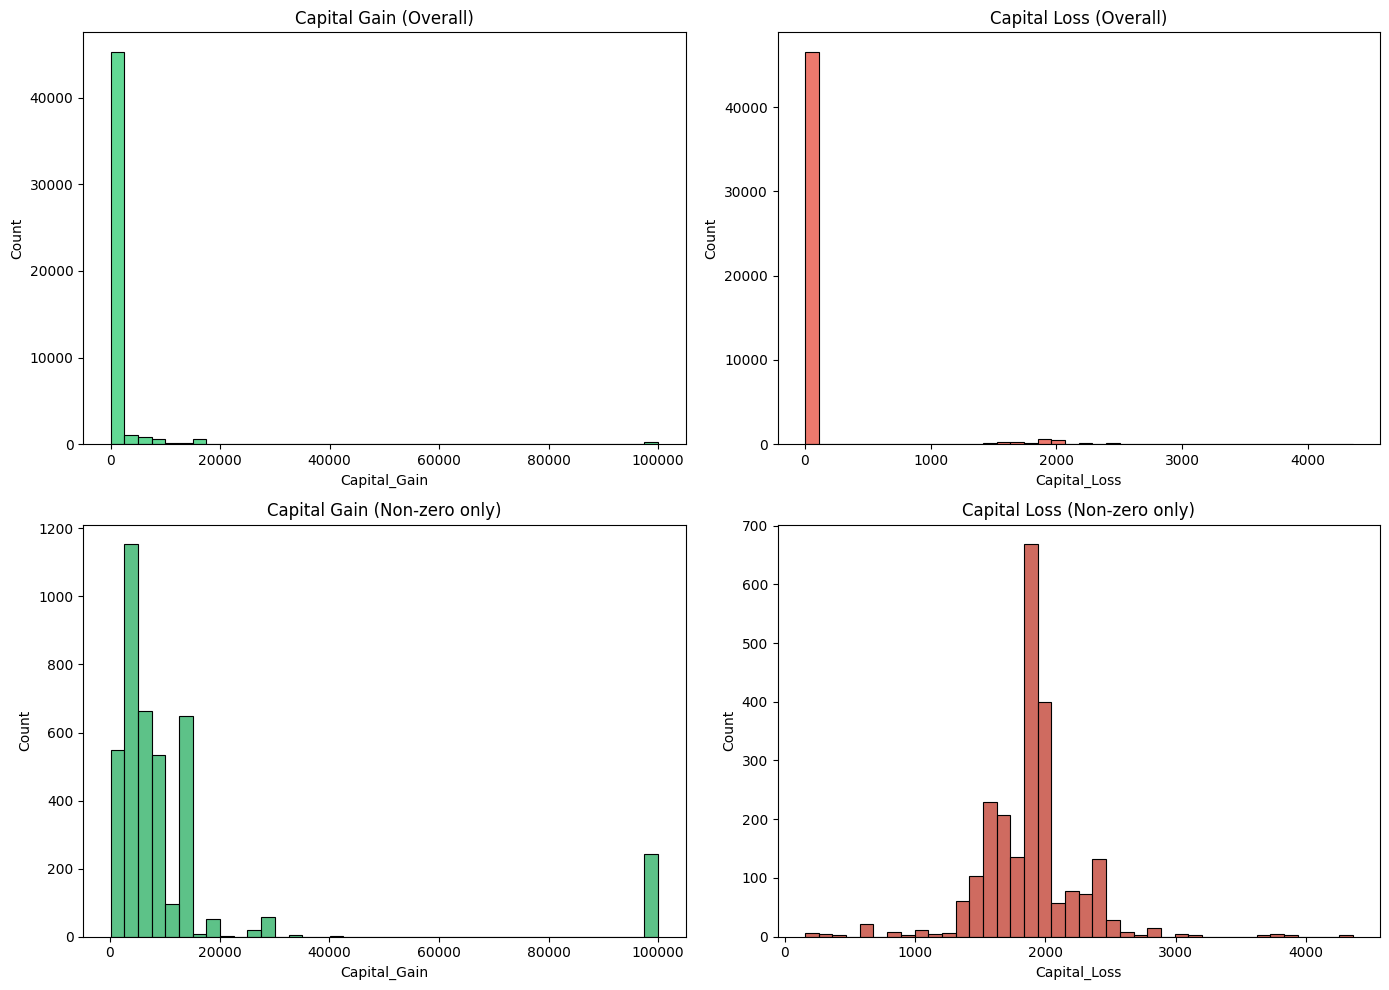

Proportion with any capital activity: 0.129 (12.9%)


In [14]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.histplot(df[cap_gain_col], bins=40, ax=axes[0,0], color='#2ecc71')
axes[0,0].set_title('Capital Gain (Overall)')

sns.histplot(df[cap_loss_col], bins=40, ax=axes[0,1], color='#e74c3c')
axes[0,1].set_title('Capital Loss (Overall)')

sns.histplot(df.loc[df[cap_gain_col] > 0, cap_gain_col], bins=40, ax=axes[1,0], color='#27ae60')
axes[1,0].set_title('Capital Gain (Non-zero only)')

sns.histplot(df.loc[df[cap_loss_col] > 0, cap_loss_col], bins=40, ax=axes[1,1], color='#c0392b')
axes[1,1].set_title('Capital Loss (Non-zero only)')

plt.tight_layout()
plt.show()

activity_rate = df['Any_Capital_Activity'].mean()
print(f"Proportion with any capital activity: {activity_rate:.3f} ({activity_rate*100:.1f}%)")

Age group summary (mean net capital, activity rate):
               Net_Capital  Activity_Rate
Age_Group                               
Freshers       116.768975       0.047676
Early_Career   516.362805       0.105351
Mid_Career    1436.904551       0.160084
Late_Career   1495.901715       0.157465
Senior        1760.648299       0.230474

Work intensity summary (mean net capital, activity rate):
                 Net_Capital  Activity_Rate
Work_Intensity                            
Unemployed              NaN            NaN
Part_Time        296.692634       0.081736
Full_Time        649.951380       0.110852
Overtime        1831.986431       0.183654
Excessive       2709.634248       0.184964


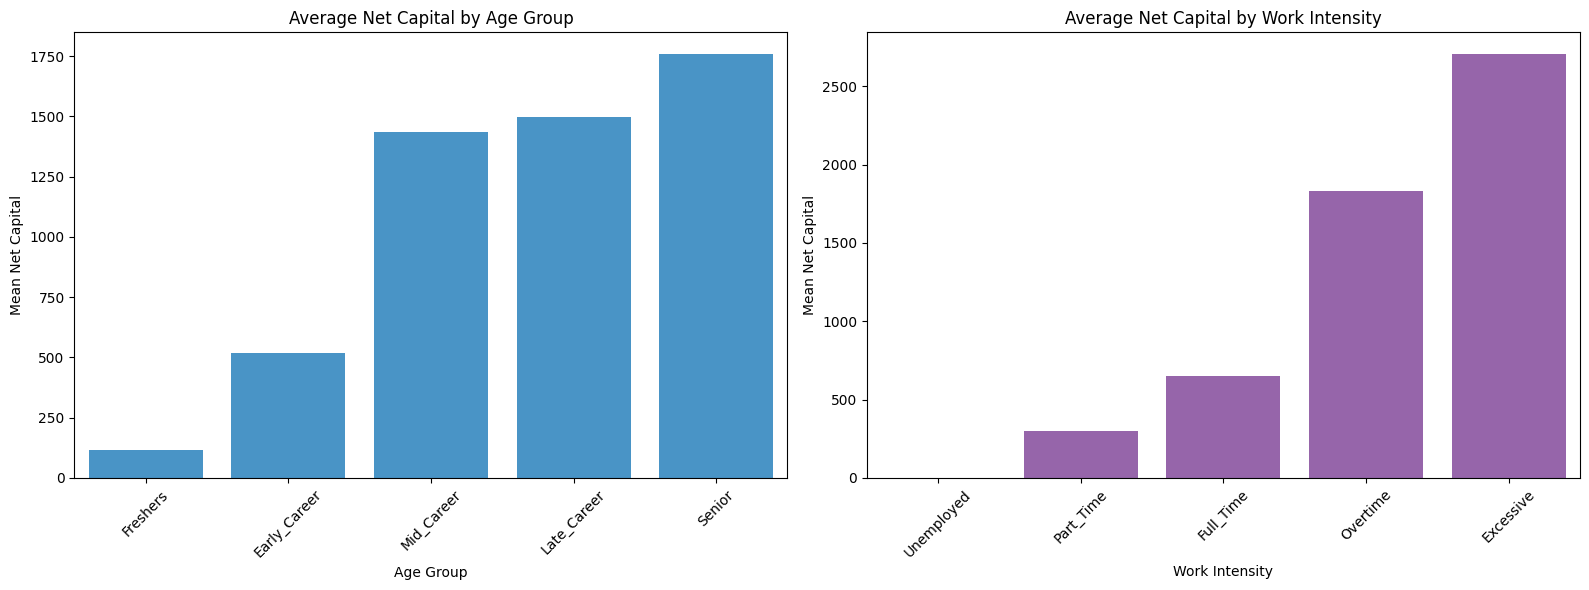

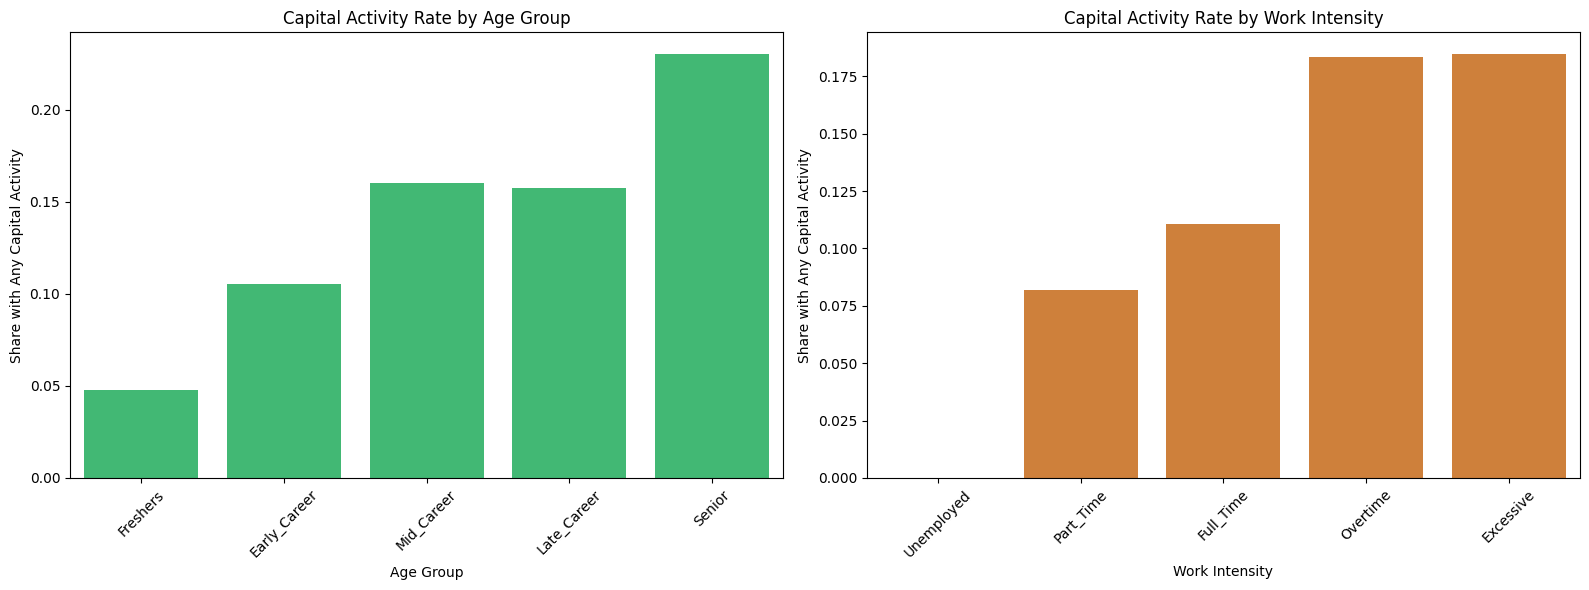

In [15]:
assert 'Age_Group' in df.columns and 'Work_Intensity' in df.columns, "Expected Age_Group and Work_Intensity to be present."

agg_funcs = {
    'Net_Capital': 'mean',
    'Any_Capital_Activity': 'mean'
}

age_summary = df.groupby('Age_Group', observed=False).agg(agg_funcs).rename(columns={'Any_Capital_Activity': 'Activity_Rate'})
work_summary = df.groupby('Work_Intensity', observed=False).agg(agg_funcs).rename(columns={'Any_Capital_Activity': 'Activity_Rate'})

print("Age group summary (mean net capital, activity rate):\n", age_summary)
print("\nWork intensity summary (mean net capital, activity rate):\n", work_summary)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Convert index to list to avoid warnings
sns.barplot(x=list(age_summary.index), y=age_summary['Net_Capital'], ax=axes[0], color='#3498db')
axes[0].set_title('Average Net Capital by Age Group')
axes[0].set_xlabel('Age Group')
axes[0].set_ylabel('Mean Net Capital')
axes[0].tick_params(axis='x', rotation=45)

sns.barplot(x=list(work_summary.index), y=work_summary['Net_Capital'], ax=axes[1], color='#9b59b6')
axes[1].set_title('Average Net Capital by Work Intensity')
axes[1].set_xlabel('Work Intensity')
axes[1].set_ylabel('Mean Net Capital')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Convert index to list to avoid warnings
sns.barplot(x=list(age_summary.index), y=age_summary['Activity_Rate'], ax=axes[0], color='#2ecc71')
axes[0].set_title('Capital Activity Rate by Age Group')
axes[0].set_xlabel('Age Group')
axes[0].set_ylabel('Share with Any Capital Activity')
axes[0].tick_params(axis='x', rotation=45)

sns.barplot(x=list(work_summary.index), y=work_summary['Activity_Rate'], ax=axes[1], color='#e67e22')
axes[1].set_title('Capital Activity Rate by Work Intensity')
axes[1].set_xlabel('Work Intensity')
axes[1].set_ylabel('Share with Any Capital Activity')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [16]:
def eta_squared(df, y, group):
    tmp = df[[y, group]].dropna()
    grand_mean = tmp[y].mean()
    ss_between = tmp.groupby(group, observed=False)[y].apply(lambda g: len(g) * (g.mean() - grand_mean)**2).sum()
    ss_total = ((tmp[y] - grand_mean)**2).sum()
    return float(ss_between / ss_total) if ss_total > 0 else 0.0

eta_age = eta_squared(df, 'Net_Capital', 'Age_Group')
eta_work = eta_squared(df, 'Net_Capital', 'Work_Intensity')
print(f"Eta^2 (Age_Group -> Net_Capital): {eta_age:.4f}")
print(f"Eta^2 (Work_Intensity -> Net_Capital): {eta_work:.4f}")

stronger = 'Age' if eta_age > eta_work else ('Work Intensity' if eta_work > eta_age else 'Tie')
print(f"Stronger association with Net Capital: {stronger}")

Eta^2 (Age_Group -> Net_Capital): 0.0058
Eta^2 (Work_Intensity -> Net_Capital): 0.0072
Stronger association with Net Capital: Work Intensity


# Final Dataset Refinement and Structure


In [17]:
raw_path = 'M25_DA_A1_Dataset1.csv'
raw_df = pd.read_csv(raw_path)

if 'Education' in raw_df.columns:
    raw_df['Education'] = raw_df['Education'].astype(str).str.strip()

summary = {}
summary['rows_before'] = len(raw_df)
summary['rows_after'] = len(df)
summary['cols_before'] = len(raw_df.columns)
summary['cols_after'] = len(df.columns)

key_vars = ['Age', 'Hours_per_week', 'Education']
key_vars = [c for c in key_vars if c in raw_df.columns and c in df.columns]
missing_before = raw_df[key_vars].isna().sum().rename('missing_before')
missing_after = df[key_vars].isna().sum().rename('missing_after')
missing_compare = pd.concat([missing_before, missing_after], axis=1)

edu_before = raw_df['Education'].value_counts(dropna=False) if 'Education' in raw_df.columns else pd.Series(dtype=int)
edu_after = df['Education_Level'].value_counts(dropna=False) if 'Education_Level' in df.columns else pd.Series(dtype=int)

new_features = []
for col in ['Education_Level', 'Age_Group', 'Work_Intensity', 'Work_Life_Balance', 'Net_Capital', 'Any_Capital_Activity']:
    if col in df.columns and col not in raw_df.columns:
        new_features.append(col)

notes = []
notes.append("Filtered Age to >=14 and >0; coerced non-numeric to NaN then imputed modes for Age and Hours_per_week.")
notes.append("Trimmed whitespace in Education; removed rows with missing Education.")
notes.append("Created grouped features: Age_Group and Work_Intensity; Education grouped into Education_Level.")
notes.append("Created Net_Capital (gain - loss) and Any_Capital_Activity flags.")

print("DATASET SHAPE")
print(pd.Series(summary))

print("\nMISSING VALUES (before vs after)")
print(missing_compare)

print("\nCATEGORY COUNTS: Education (before)")
print(edu_before.head(20))
print("\nCATEGORY COUNTS: Education_Level (after)")
print(edu_after)

print("\nNEW TRANSFORMED GROUPED FEATURES")
print(new_features)

print("\nREFINEMENT NOTES")
for n in notes:
    print("- ", n)

if 'Age_Group' in df.columns and 'Age' in df.columns:
    age_unique = df['Age'].nunique()
    age_groups = df['Age_Group'].nunique()
    print(f"\nAge grouping: {age_unique} unique numeric values -> {age_groups} categories")
if 'Work_Intensity' in df.columns and 'Hours_per_week' in df.columns:
    h_unique = df['Hours_per_week'].nunique()
    h_groups = df['Work_Intensity'].nunique()
    print(f"Work intensity grouping: {h_unique} unique numeric values -> {h_groups} categories")

DATASET SHAPE
rows_before    48843
rows_after     48842
cols_before       15
cols_after        21
dtype: int64

MISSING VALUES (before vs after)
                missing_before  missing_after
Age                          0              0
Hours_per_week               1              0
Education                    0              0

CATEGORY COUNTS: Education (before)
Education
HS-grad         15784
Some-college    10878
Bachelors        8025
Masters          2657
Assoc-voc        2061
11th             1812
Assoc-acdm       1601
10th             1389
7th-8th           955
Prof-school       834
9th               756
12th              657
Doctorate         594
5th-6th           509
1st-4th           247
Preschool          83
nan                 1
Name: count, dtype: int64

CATEGORY COUNTS: Education_Level (after)
Education_Level
High School      24060
Undergraduate    18903
Postgraduate      4085
School            1711
Kindergarten        83
Name: count, dtype: int64

NEW TRANSFORMED GROUPED 

In [18]:
# Save the refined dataset as CSV file
refined_dataset_path = 'M25_DA_A1_Dataset1_Refined.csv'
df.to_csv(refined_dataset_path, index=False)
print(f"✅ Refined dataset saved as: {refined_dataset_path}")
print(f"📊 Dataset shape: {df.shape}")
print(f"💾 File size: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

# Display refined dataset structure and sample
print("\n" + "="*60)
print("REFINED DATASET STRUCTURE")
print("="*60)
print(f"Columns ({len(df.columns)}):")
for i, col in enumerate(df.columns, 1):
    dtype = str(df[col].dtype)
    unique_vals = df[col].nunique()
    print(f"{i:2d}. {col:<20} | {dtype:<12} | {unique_vals:>6} unique values")

print("\n" + "="*60)
print("REFINED DATASET SAMPLE (First 5 rows)")
print("="*60)
print(df.head())

print("\n" + "="*60)
print("KEY TRANSFORMATIONS SUMMARY")
print("="*60)
transformations = {
    'Original categorical variables': ['Age (74 unique)', 'Hours_per_week (96 unique)', 'Education (16 unique)'],
    'New grouped variables': ['Age_Group (5 categories)', 'Work_Intensity (5 categories)', 'Education_Level (5 categories)'],
    'Engineered features': ['Net_Capital', 'Any_Capital_Activity', 'Work_Life_Balance'],
    'Data quality improvements': ['Missing value imputation', 'Age validation (≥14)', 'Whitespace cleaning']
}

for category, items in transformations.items():
    print(f"\n{category.upper()}:")
    for item in items:
        print(f"  • {item}")

✅ Refined dataset saved as: M25_DA_A1_Dataset1_Refined.csv
📊 Dataset shape: (48842, 21)
💾 File size: 33.46 MB

REFINED DATASET STRUCTURE
Columns (21):
 1. Age                  | int64        |     74 unique values
 2. Workclass            | object       |      8 unique values
 3. fnlwgt               | float64      |  28523 unique values
 4. Education            | object       |     16 unique values
 5. Education_Num        | float64      |     16 unique values
 6. Martial_Status       | object       |      7 unique values
 7. Occupation           | object       |     14 unique values
 8. Relationship         | object       |      6 unique values
 9. Race                 | object       |      5 unique values
10. Sex                  | object       |      2 unique values
11. Capital_Gain         | float64      |    123 unique values
12. Capital_Loss         | float64      |     99 unique values
13. Hours_per_week       | float64      |     96 unique values
14. Country              | obj